# Two overlapping planetary orbits from Doppler data

This review actively solves the complete 401-observation HD 164922 inverse problem. The physical unknowns are two sets of orbital elements plus three spectrometer offsets and three jitter standard deviations. The independent original result is a numerical method reference, **not measured true orbital elements**. The selected published stage is the full-data maximum a posteriori (MAP) point estimate, with independent precision continuation of the same posterior to resolve premature default stopping. The native early-stop result remains a labeled comparison; no finite chain is presented as a converged posterior.

## 1. Observe the signal and sampling

A gravitationally perturbed star moves along our line of sight. Its Doppler velocity contains two superposed periodic Keplerian signals, instrument zero points and noise. The full native observations are retained, without nightly averaging. Observation uncertainties exclude the unknown instrument jitter.

Kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe


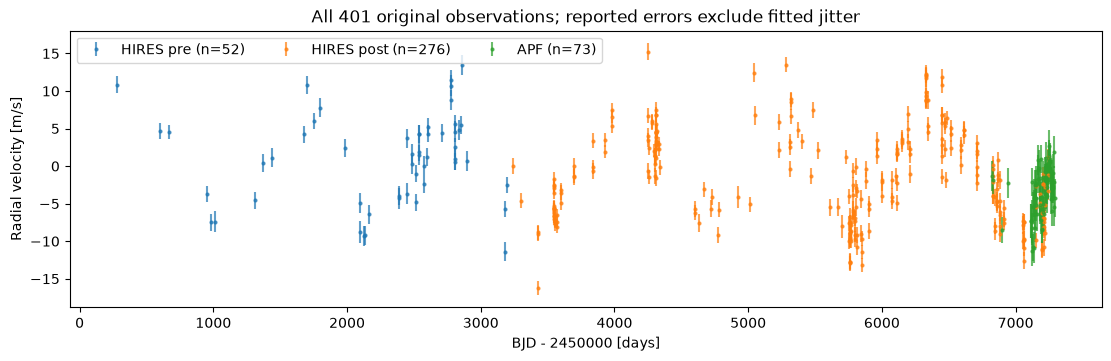

In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
root=Path.cwd()
if not (root/'src').is_dir():root=root.parent
assert (root/'data/raw_data.npz').is_file()
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.physics_model import solve_kepler,components,forward,unpack_orbits
from src.solvers import INITIAL,reconstruct,reconstruct_native,submission,negative_logposterior
from src.visualization import residual_diagnostics,parameter_errors,plot_observations,plot_fit,plot_phases
print('Kernel:',sys.executable)
data=load_data()
plot_observations(data);plt.show()

## 2. Physics and the role of the reference

For time $t$ and instrument index $s$, the full predicted velocity is

$$
v(t,s)=\gamma_s+\sum_{p=1}^{2}K_p[\cos(\nu_p(t)+\omega_p)+e_p\cos\omega_p].
$$

Here $\gamma$ is an offset, $K$ a positive velocity amplitude, $e$ eccentricity, $\omega$ stellar argument of periastron and $\nu$ true anomaly. Each orbit has a period $P$ and inferior-conjunction epoch $T$. Convert conjunction to periastron using true anomaly $\pi/2-\omega$, then solve $E-e\sin E=M$ for eccentric anomaly $E$ and mean anomaly $M=2\pi\operatorname{frac}((t-t_p)/P)$, where $t_p$ is the periastron epoch. The true anomaly follows the standard eccentric-anomaly transformation given in the README.

The objective is the sum of Gaussian negative log likelihood and the negative log of the specified period, epoch and physical priors. The measurement variance is $\sigma_n^2+j_s^2$, with known instrumental uncertainty $\sigma$ and inferred jitter $j$. Both the squared residual and log variance terms are required. We optimise the sixteen native coordinates with Powell direction sets and explicit local Kepler updates.

The original source independently fitted these exact observations. Its arrays are loaded only after the fresh fit, for comparison. No physical ground truth is available. The figures distinguish this original run from the fresh local reconstruction.

The published phase-fold comparison also includes binned velocities. The local plot preserves this comparison by applying the native 25-bin summary over two repeated cycles (about 0.08 cycle bins), retaining bins with at least three observations and showing their unweighted mean and standard error. The native centred phase cycle and fitted total uncertainty bars are retained; all observations remain in the inverse fit.

The original default function tolerance stopped before a stable optimum. We independently ran the unchanged author posterior API from four starts at higher precision before extracting the same affine conditioning and direction-set search locally. All four author runs agree within 1.16e-11 in objective. Scoring tolerances remain unchanged; an arbitrary early stopping point is no longer the target.

Default-stop local/original max parameter difference: 6.874138489365578e-05
Default-stop saved model discrepancy [m/s]: 8.572070602674842e-06
{
  "fresh_seconds": 11.97571120003704,
  "success": true,
  "message": "Optimization terminated successfully.",
  "iterations": 31,
  "evaluations": 15007,
  "negative_logposterior": 1039.914080987055,
  "selected_start": 0,
  "runs": [
    {
      "success": true,
      "message": "Optimization terminated successfully.",
      "iterations": 31,
      "evaluations": 15007,
      "negative_logposterior": 1039.914080987055
    },
    {
      "success": true,
      "message": "Optimization terminated successfully.",
      "iterations": 25,
      "evaluations": 12478,
      "negative_logposterior": 1039.9140809870696
    },
    {
      "success": true,
      "message": "Optimization terminated successfully.",
      "iterations": 35,
      "evaluations": 16743,
      "negative_logposterior": 1039.9140809870714
    },
    {
      "success": true,
    

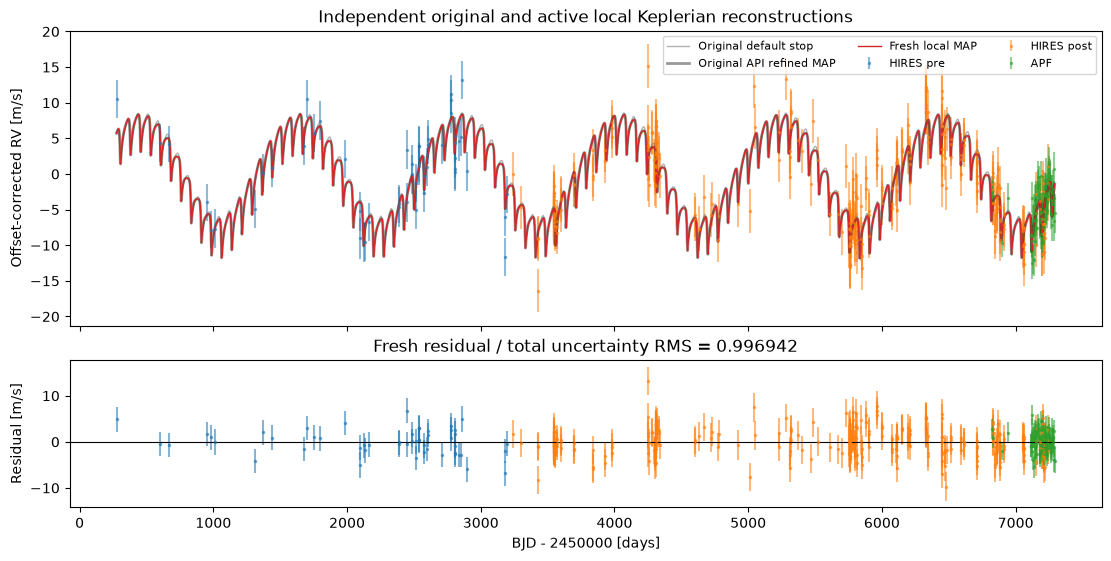

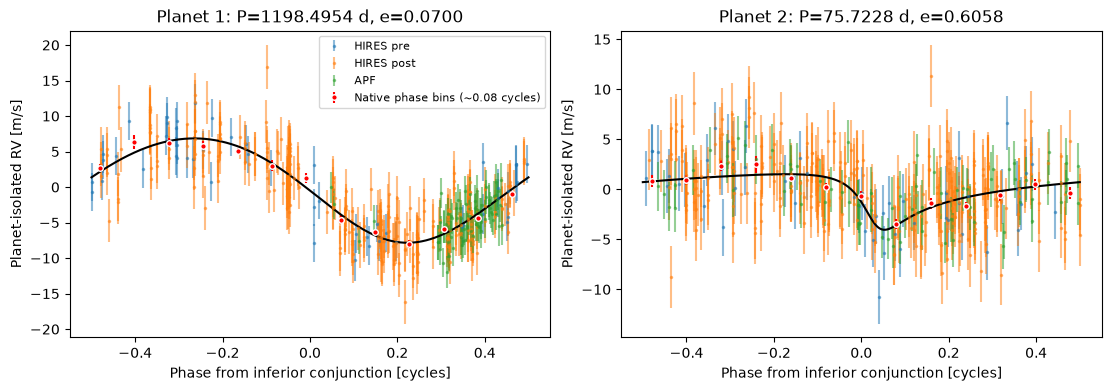

In [2]:
start=time.perf_counter()
vector,diagnostics=reconstruct(data)
fresh_seconds=time.perf_counter()-start
with np.load(root/'notebooks/reference_outputs/upstream_map.npz',allow_pickle=False) as z:
    original=z['vector'].copy();original_model=z['model'].copy()
    native_original=z['native_vector'].copy();native_original_model=z['native_model'].copy()
native_fresh,native_diagnostics=reconstruct_native(data)
print('Default-stop local/original max parameter difference:',np.max(np.abs(native_fresh-native_original)))
print('Default-stop saved model discrepancy [m/s]:',np.max(np.abs(native_original_model-components(data['time'],native_fresh).sum(0))))
physical=unpack_orbits(vector);original_physical=unpack_orbits(original)
residual,total_sigma,weighted_rms=residual_diagnostics(data,vector)
print(json.dumps({'fresh_seconds':fresh_seconds,**diagnostics},indent=2))
print('Original saved model versus fresh planet sum, RMS [m/s]:',np.sqrt(np.mean((original_model-components(data['time'],vector).sum(0))**2)))
print('Physical absolute errors (ten orbit entries then six instrument entries):',parameter_errors(vector,original))
plot_fit(data,vector,original,native_original);plt.show()
plot_phases(data,vector);plt.show()

## 3. Recovered parameters and orbital geometry

Each table entry is computed from its identified fit. The ellipse views show the shape implied by the recovered eccentricity, using a unit semi-major axis and the focus at the star. These are **normalised orbital-plane shapes**, not resolved sky images or measurements of inclination. Radial velocities alone leave inclination unconstrained; no true planet mass is claimed. The bottom panels report every instrument offset and jitter, so nuisance inference remains visible.

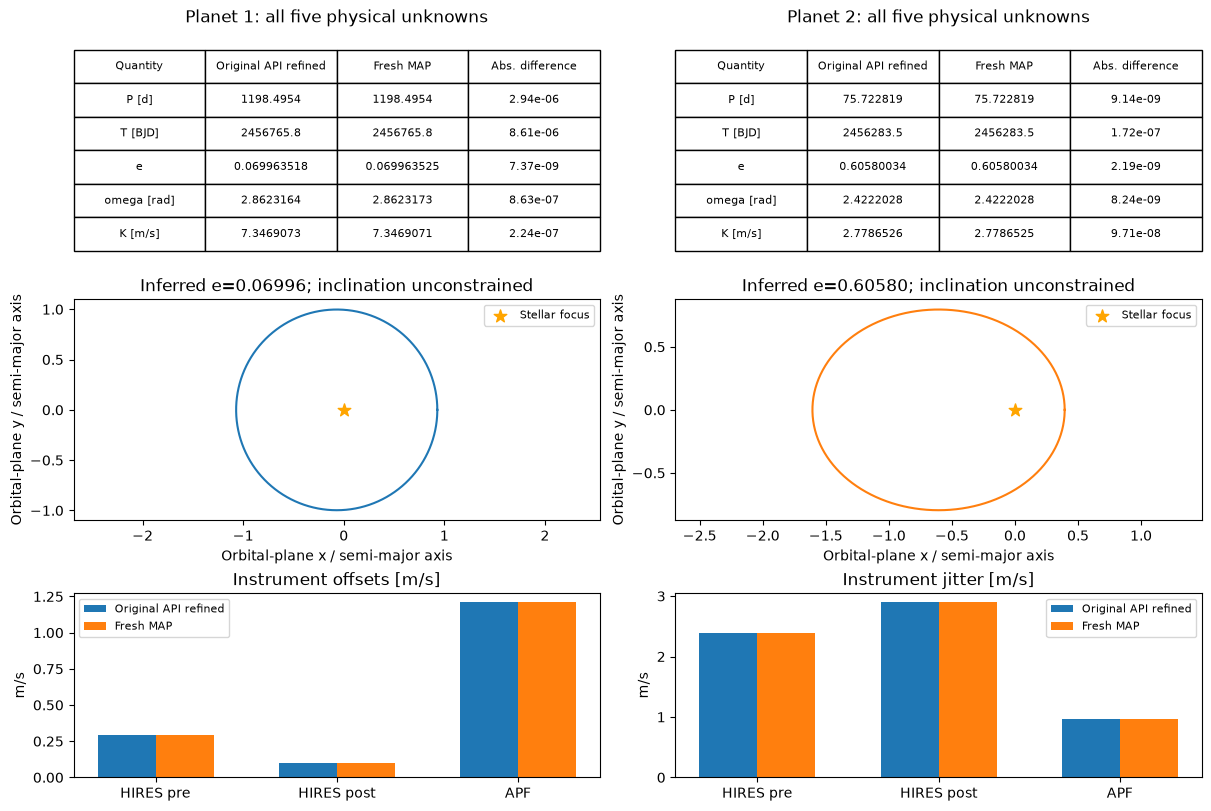

In [3]:
fig=plt.figure(figsize=(12,8),layout='constrained');gs=fig.add_gridspec(3,2,height_ratios=[1.3,1.2,1])
labels=['P [d]','T [BJD]','e','omega [rad]','K [m/s]']
for j in range(2):
    ax=fig.add_subplot(gs[0,j]);ax.axis('off')
    rows=[[label,f'{original_physical[j,i]:.8g}',f'{physical[j,i]:.8g}',f'{abs(physical[j,i]-original_physical[j,i]):.3g}'] for i,label in enumerate(labels)]
    tab=ax.table(cellText=rows,colLabels=['Quantity','Original API refined','Fresh MAP','Abs. difference'],cellLoc='center',loc='center');tab.auto_set_font_size(False);tab.set_fontsize(8);tab.scale(1,1.7);ax.set_title(f'Planet {j+1}: all five physical unknowns')
    ax=fig.add_subplot(gs[1,j]);E=np.linspace(0,2*np.pi,401);e=physical[j,2]
    ax.plot(np.cos(E)-e,np.sqrt(1-e*e)*np.sin(E),color=f'C{j}');ax.scatter([0],[0],marker='*',s=90,color='orange',label='Stellar focus')
    ax.set(xlabel='Orbital-plane x / semi-major axis',ylabel='Orbital-plane y / semi-major axis',title=f'Inferred e={e:.5f}; inclination unconstrained');ax.axis('equal');ax.legend(fontsize=8)
for j,(sl,title) in enumerate([(slice(10,13),'Instrument offsets [m/s]'),(slice(13,16),'Instrument jitter [m/s]')]):
    ax=fig.add_subplot(gs[2,j]);x=np.arange(3);ax.bar(x-.16,original[sl],.32,label='Original API refined');ax.bar(x+.16,vector[sl],.32,label='Fresh MAP');ax.set(xticks=x,xticklabels=['HIRES pre','HIRES post','APF'],ylabel='m/s',title=title);ax.legend(fontsize=8)
plt.show()

## 4. Observation residuals and independent physics checks

A good parameter match alone does not establish that the model explains the observations. We examine residuals divided by the fitted total uncertainty separately for all three instruments. The quantile plot compares their empirical distribution with a standard Gaussian; departures can reflect stellar activity, remaining companions or noise-model limitations. The independent equation-residual curve checks the explicit Kepler solve over a broad eccentricity range, including 0.99.

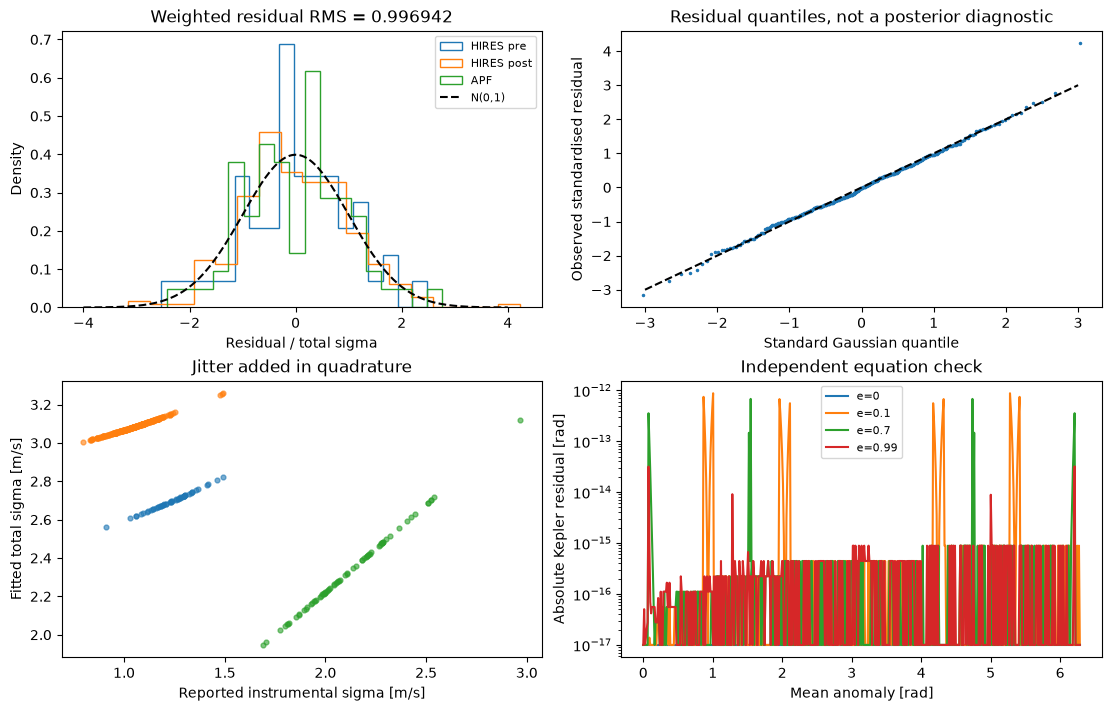

In [4]:
fig,ax=plt.subplots(2,2,figsize=(11,7),layout='constrained')
z=residual/total_sigma
for k,label in enumerate(['HIRES pre','HIRES post','APF']):
    m=data['instrument']==k;ax[0,0].hist(z[m],bins=18,density=True,histtype='step',label=label)
    ax[1,0].scatter(data['uncertainty'][m],total_sigma[m],s=12,alpha=.6,label=label)
xx=np.linspace(-4,4,201);ax[0,0].plot(xx,norm.pdf(xx),color='k',ls='--',label='N(0,1)');ax[0,0].set(xlabel='Residual / total sigma',ylabel='Density',title=f'Weighted residual RMS = {weighted_rms:.6f}');ax[0,0].legend(fontsize=8)
q=norm.ppf((np.arange(len(z))+.5)/len(z));ax[0,1].plot(q,np.sort(z),'.',ms=3);ax[0,1].plot([-3,3],[-3,3],'k--');ax[0,1].set(xlabel='Standard Gaussian quantile',ylabel='Observed standardised residual',title='Residual quantiles, not a posterior diagnostic')
ax[1,0].set(xlabel='Reported instrumental sigma [m/s]',ylabel='Fitted total sigma [m/s]',title='Jitter added in quadrature')
M=np.linspace(0,2*np.pi,501)
for e in [0,.1,.7,.99]:
    E=solve_kepler(M,e);ax[1,1].semilogy(M,np.maximum(abs(E-e*np.sin(E)-M),1e-17),label=f'e={e}')
ax[1,1].set(xlabel='Mean anomaly [rad]',ylabel='Absolute Kepler residual [rad]',title='Independent equation check');ax[1,1].legend(fontsize=8);plt.show()

## 5. Fit ablations on the same observations

The fresh initial guess, circular-orbit restriction, fixed zero offsets and almost-zero fixed jitter test which physical terms explain the observations. Each restricted fit is actually recomputed with the same objective and data. The near-zero jitter is 0.001 m/s so it remains strictly inside the prior support. The initial guess is labelled explicitly and is not a reconstruction. Lower negative log posterior is better; weighted residual RMS near one is expected only if the noise scale is adequate. Jitter is fitted jointly in the unrestricted and other applicable models, so their raw residual RMS is also shown.

The native default-stop result is compared explicitly with the improved MAP, and a separate precision continuation checks stability of the improved point. The public problem is the well-converged posterior estimate, without requiring a particular starting vector or arbitrary early stopping rule.

Warm continuation changes internal parameters by: [ 3.21570815e-06 -5.79096377e-06 -8.15507256e-09  6.99235752e-08
  1.09604172e-08  2.06682671e-10  1.86264515e-08  0.00000000e+00
  0.00000000e+00  1.34873668e-10  1.90600868e-11  1.56099541e-08
  1.12607701e-11 -5.66886604e-08  7.84201735e-08  1.76891835e-11]


Computed ablation table: [('Native initial guess', [1232.2737367721134, 4.072643500998324, 1.3902952320766164]), ('Native default stop', [1040.5577107032364, 2.9062283781489295, 0.9963588232039429]), ('Full precision MAP', [1039.914080987055, 2.904231061893223, 0.996942193594173]), ('Precision continuation', [1039.9140809870526, 2.904231063992337, 0.9969421795196123]), ('Circular orbits', [1050.5065488287341, 2.96838285986761, 0.9949177886499223]), ('Zero instrument offsets', [1044.6249286875045, 2.9286013033321354, 0.9974069271448347]), ('Near-zero jitter', [1842.3766368933382, 2.9120593102156938, 2.5930208113313333])]


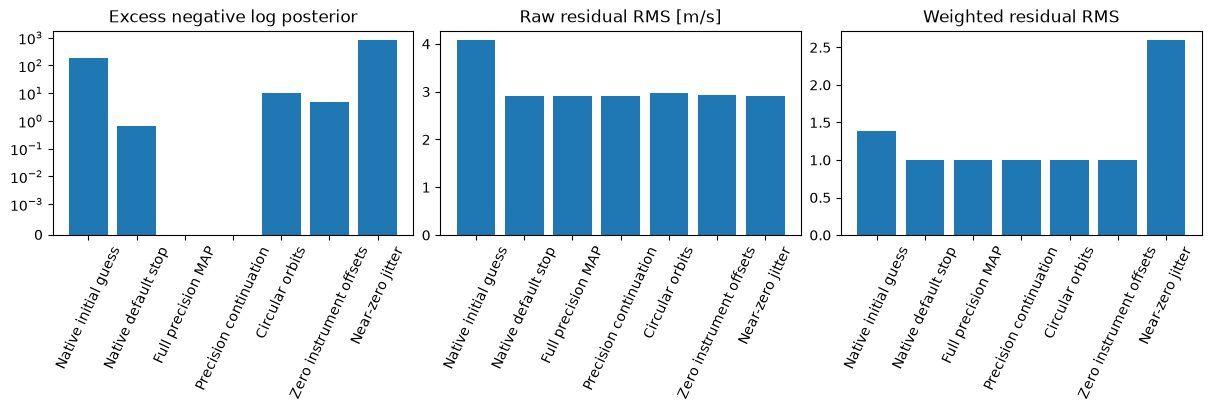

In [5]:
warm_vector,warm_diagnostics=reconstruct(data,initial=vector)
ablation_vectors=[INITIAL.copy(),native_fresh.copy(),vector.copy(),warm_vector]
ablation_names=['Native initial guess','Native default stop','Full precision MAP','Precision continuation']
print('Warm continuation changes internal parameters by:',warm_vector-vector)
ablation_diagnostics=[]
for label,fixed in [('Circular orbits',{2:0.,3:0.,7:0.,8:0.}),('Zero instrument offsets',{10:0.,11:0.,12:0.}),('Near-zero jitter',{13:.001,14:.001,15:.001})]:
    v,r=reconstruct(data,initial=vector,fixed=fixed);ablation_vectors.append(v);ablation_names.append(label);ablation_diagnostics.append(r)
summary=[]
for label,v in zip(ablation_names,ablation_vectors):
    r,s,w=residual_diagnostics(data,v);summary.append([negative_logposterior(v,data),np.sqrt(np.mean(r*r)),w])
summary=np.asarray(summary)
fig,ax=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for j,title in enumerate(['Excess negative log posterior','Raw residual RMS [m/s]','Weighted residual RMS']):
    values=summary[:,j]-summary[:,j].min() if j==0 else summary[:,j]
    ax[j].bar(np.arange(len(summary)),values)
    if j==0:ax[j].set_yscale('symlog',linthresh=.001)
    ax[j].set(xticks=np.arange(len(summary)),xticklabels=ablation_names,title=title);ax[j].tick_params(axis='x',rotation=65)
print('Computed ablation table:',list(zip(ablation_names,summary.tolist())));plt.show()

## 6. Noise sensitivity, limits and conclusion

We perturb every original velocity by a new independent Gaussian draw using its freshly fitted total noise standard deviation, and rerun the complete sixteen-parameter fit. These are local noise-sensitivity experiments started from the active solution. They are **not posterior samples**, do not prove global mode discovery and do not provide a coverage guarantee. The plotted scatter can be much larger than original-versus-local numerical differences: method parity and physical uncertainty answer different questions.

Every figure above uses actively computed arrays. The accepted output is the unrestricted full-data MAP; ablations and perturbation experiments are separately identified. The two-planet model explains these historical velocities with weighted residual RMS near one, while irregular sampling, additional stellar variability and unmeasured inclination limit physical interpretation.

The circular restriction gives a modest likelihood tradeoff, and perturbation refits show broad eccentricity scatter. The many displayed digits establish numerical reproduction, not a claim of that precision in the real orbital elements. The time-domain fit and phase-bin comparison preserve the published MAP review panels; the centred phase convention and total uncertainty bars are preserved.

32 refits seconds: 88.0064269999857 successful: 32
Noise-refit standard deviations in native physical units: [ 4.98451595 15.61659891  0.04577932  0.54044115  0.21337535  0.03639213
  5.55008286  0.22402282  0.94458446  1.06922691  0.39369925  0.20329428
  0.36352738  0.36881933  0.16733444  0.36339866]


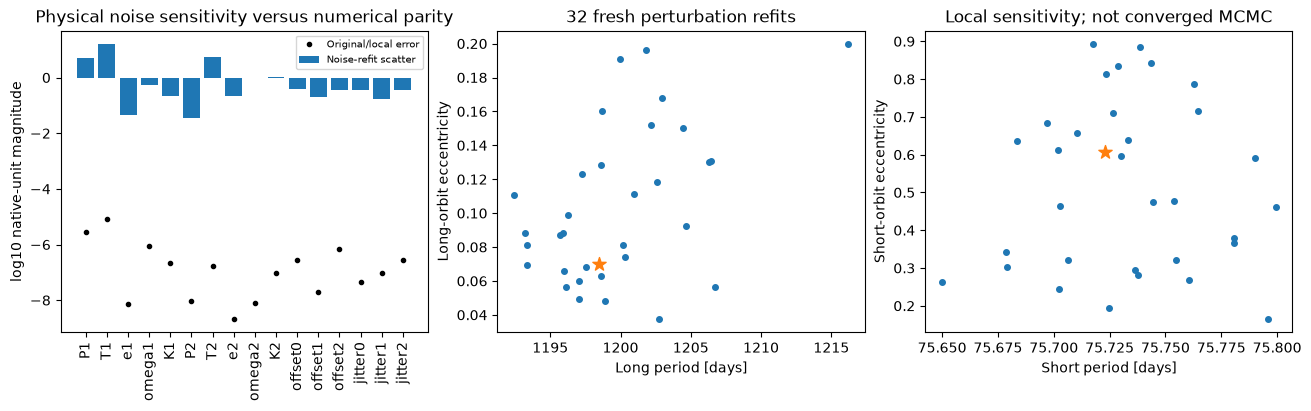

Fresh full-output Judge: {
  "status": "pass",
  "passed": true,
  "metrics": {
    "period_abs_day": 2.940933427453274e-06,
    "epoch_phase_abs_day": 8.607283234596252e-06,
    "eccentricity_abs": 7.373432905910526e-09,
    "omega_phase_abs_rad": 8.631959618199404e-07,
    "amplitude_abs_mps": 2.24392920245009e-07,
    "offset_abs_mps": 7.143053568636759e-07,
    "jitter_abs_mps": 2.7228318488781156e-07,
    "weighted_residual_rms": 0.996942193594158
  },
  "thresholds": {
    "period_abs_day": {
      "comparison": "<=",
      "boundary": 0.001
    },
    "epoch_phase_abs_day": {
      "comparison": "<=",
      "boundary": 0.001
    },
    "eccentricity_abs": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "omega_phase_abs_rad": {
      "comparison": "<=",
      "boundary": 0.001
    },
    "amplitude_abs_mps": {
      "comparison": "<=",
      "boundary": 0.001
    },
    "offset_abs_mps": {
      "comparison": "<=",
      "boundary": 0.001
    },
    "jitter_abs_mp

In [6]:
rng=np.random.default_rng(71024);perturbed=[];noise_diagnostics=[]
start=time.perf_counter()
for repeat in range(32):
    noisy={k:v.copy() for k,v in data.items()};noisy['velocity']+=rng.normal(size=len(total_sigma))*total_sigma
    v,r=reconstruct(noisy,initial=vector);perturbed.append(np.r_[unpack_orbits(v).ravel(),v[10:]]);noise_diagnostics.append(r)
perturbed=np.asarray(perturbed);centre=np.r_[physical.ravel(),vector[10:]];scatter=perturbed-centre
scatter[:,1]=(scatter[:,1]+physical[0,0]/2)%physical[0,0]-physical[0,0]/2
scatter[:,6]=(scatter[:,6]+physical[1,0]/2)%physical[1,0]-physical[1,0]/2
for j in [3,8]:scatter[:,j]=np.angle(np.exp(1j*scatter[:,j]))
noise_std=scatter.std(axis=0,ddof=1);numerical_error=parameter_errors(vector,original)
fig,ax=plt.subplots(1,3,figsize=(13,4),layout='constrained')
all_labels=[f'{name}{j+1}' for j in range(2) for name in ['P','T','e','omega','K']]+['offset0','offset1','offset2','jitter0','jitter1','jitter2']
ax[0].bar(np.arange(16),np.log10(np.maximum(noise_std,1e-15)),label='Noise-refit scatter');ax[0].plot(np.arange(16),np.log10(np.maximum(numerical_error,1e-15)),'k.',label='Original/local error');ax[0].set(xticks=np.arange(16),xticklabels=all_labels,ylabel='log10 native-unit magnitude',title='Physical noise sensitivity versus numerical parity');ax[0].tick_params(axis='x',rotation=90);ax[0].legend(fontsize=7)
ax[1].scatter(perturbed[:,0],perturbed[:,2],s=16);ax[1].scatter([physical[0,0]],[physical[0,2]],marker='*',s=100);ax[1].set(xlabel='Long period [days]',ylabel='Long-orbit eccentricity',title='32 fresh perturbation refits')
ax[2].scatter(perturbed[:,5],perturbed[:,7],s=16);ax[2].scatter([physical[1,0]],[physical[1,2]],marker='*',s=100);ax[2].set(xlabel='Short period [days]',ylabel='Short-orbit eccentricity',title='Local sensitivity; not converged MCMC')
print('32 refits seconds:',time.perf_counter()-start,'successful:',sum(r['success'] for r in noise_diagnostics))
print('Noise-refit standard deviations in native physical units:',noise_std)
plt.show()
# Evaluate the actively computed unrestricted fit using the independent standalone Judge.
import importlib.util
np.savez_compressed(root/'output/reconstruction.npz',**submission(vector))
spec=importlib.util.spec_from_file_location('review_judge',root/'evaluation/judge.py')
judge_module=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge_module)
fresh_report=judge_module.judge(root/'output/reconstruction.npz')
print('Fresh full-output Judge:',json.dumps(fresh_report,indent=2))
assert fresh_report['passed']

with np.load(root/'notebooks/reference_outputs/fresh_measurements.npz',allow_pickle=False) as z:
    print('Previously measured local rerun (historical comparison only), seconds:',z['runtime_seconds'][0])
    print('Active/local archived parameter maximum difference:',np.max(np.abs(vector-z['vector'])))
